# Rolling SNR Analysis
Load results from `rolling_snr.py` and visualise SNR over time.

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

# ── Paths ─────────────────────────────────────────────────────────────────
OUTPUT_DIR = Path(r"/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/rolling_snr")

snr_data   = np.load(OUTPUT_DIR / "rolling_snr.npz")
params     = json.loads((OUTPUT_DIR / "params.json").read_text())

t          = snr_data["window_centers_s"]          # (n_windows,)  seconds
mean_snr   = snr_data["mean_snr"]                  # (n_windows,)
median_snr = snr_data["median_snr"]                # (n_windows,)
counts     = snr_data["spike_counts"]              # (n_windows,)

min_spikes = params.get("min_spikes", 10)
valid      = counts >= min_spikes

print(f"Recording length : {params['total_s']/60:.1f} min")
print(f"Windows total    : {len(t)}")
print(f"Windows valid    : {valid.sum()}  (≥ {min_spikes} spikes)")
print(f"Overall mean SNR : {params['overall_mean_snr']:.3f}")
print(f"Overall median   : {params['overall_median_snr']:.3f}")
print(f"Overall range    : [{params['overall_min_snr']:.3f}, {params['overall_max_snr']:.3f}]")

Recording length : 601.2 min
Windows total    : 7211
Windows valid    : 7211  (≥ 10 spikes)
Overall mean SNR : 3.650
Overall median   : 3.658
Overall range    : [3.253, 4.213]


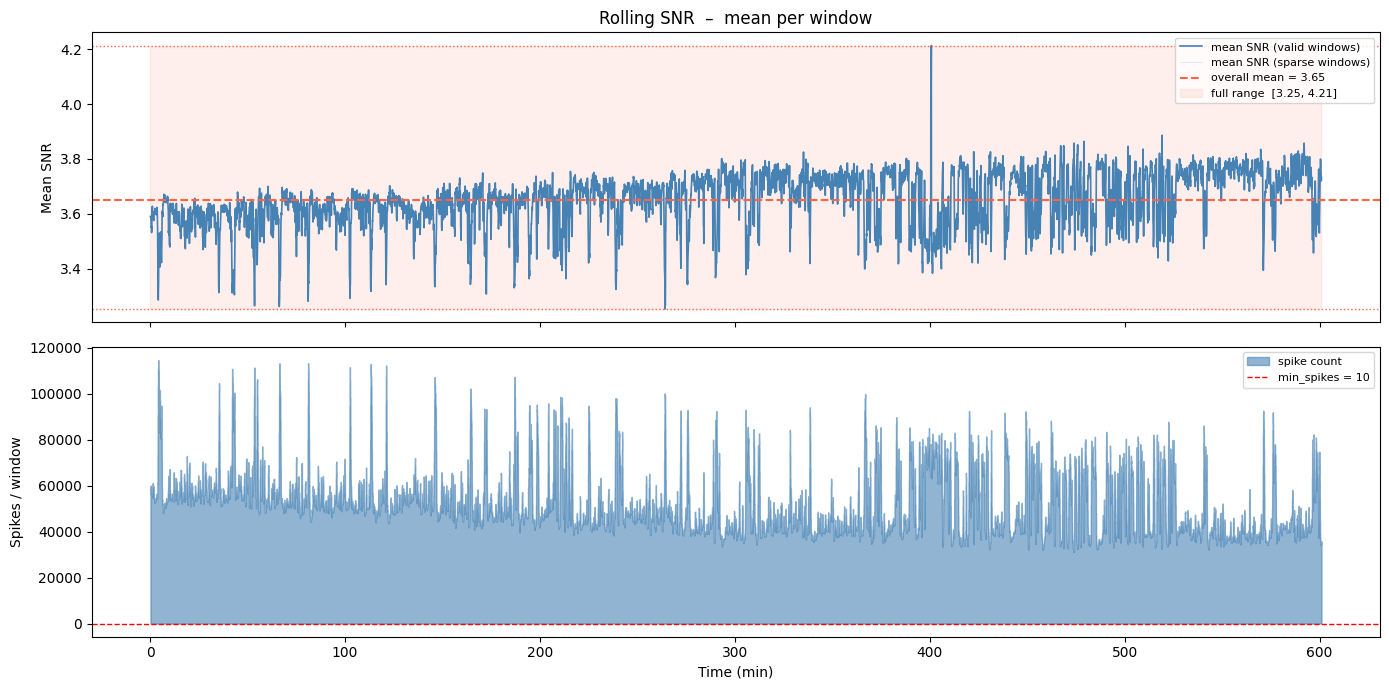


Mean SNR : 3.650  (+0.564 / -0.397)  range [3.253, 4.213]


In [4]:
# ── Rolling SNR over time ─────────────────────────────────────────────────
t_min = t / 60.0

overall_mean = np.nanmean(mean_snr[valid])
snr_min      = np.nanmin(mean_snr[valid])
snr_max      = np.nanmax(mean_snr[valid])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# ── Top: mean SNR per window ───────────────────────────────────────────────
ax = axes[0]
ax.plot(t_min[valid],  mean_snr[valid],   lw=1.2, color="steelblue",  label="mean SNR (valid windows)")
ax.plot(t_min[~valid], mean_snr[~valid],  lw=0.6, color="lightblue",  alpha=0.5, label="mean SNR (sparse windows)")
ax.axhline(overall_mean, color="tomato",  lw=1.5, ls="--", label=f"overall mean = {overall_mean:.2f}")
ax.axhline(snr_max,      color="tomato",  lw=1.0, ls=":")
ax.axhline(snr_min,      color="tomato",  lw=1.0, ls=":")
ax.fill_between(
    [t_min[0], t_min[-1]],
    snr_min, snr_max,
    color="tomato", alpha=0.10,
    label=f"full range  [{snr_min:.2f}, {snr_max:.2f}]",
)
ax.set_ylabel("Mean SNR")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Rolling SNR  –  mean per window")

# ── Bottom: spike count per window ────────────────────────────────────────
ax2 = axes[1]
ax2.fill_between(t_min, counts, step="mid", alpha=0.6, color="steelblue", label="spike count")
ax2.axhline(min_spikes, color="red", lw=1.0, ls="--", label=f"min_spikes = {min_spikes}")
ax2.set_ylabel("Spikes / window")
ax2.set_xlabel("Time (min)")
ax2.legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "rolling_snr_over_time.png", dpi=150)
plt.show()

print(f"\nMean SNR : {overall_mean:.3f}  (+{snr_max - overall_mean:.3f} / -{overall_mean - snr_min:.3f})  "
      f"range [{snr_min:.3f}, {snr_max:.3f}]")


/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Loading recording for static noise estimate...


noise_level (no parallelization): 100%|██████████| 20/20 [00:07<00:00,  2.80it/s]


  Static noise: mean=0.9639  min=0.6021  max=1.3633
Peaks          : 129,418,393
Amplitude window: 30.0 s  →  1203 windows
Noise source   : static
Threshold      : 3.3


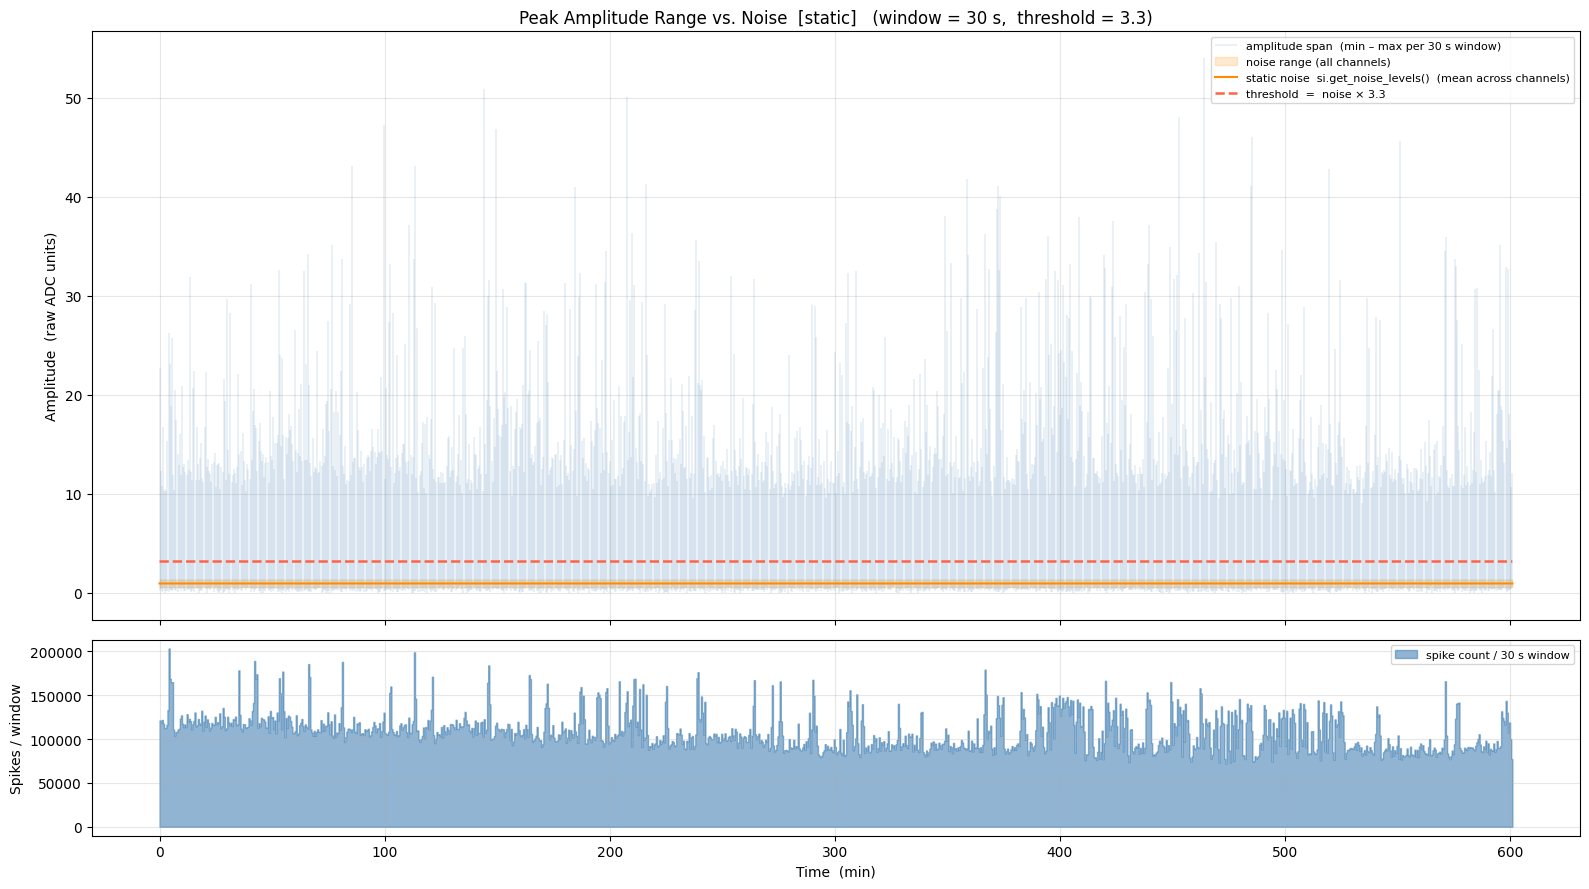

In [9]:

# ════════════════════════════════════════════════════════════════════════════
# Amplitude range vs. noise level
# ════════════════════════════════════════════════════════════════════════════
# CONFIG ─────────────────────────────────────────────────────────────────────
PEAKS_FILE         = Path(r"/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks/peaks_combined2_sorted.npy")
ROLLING_NOISE_FILE = Path(r"/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/rolling_snr/rolling_noise_levels.npz")
RECORDING_PATH     = Path(r"/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed")  # for static noise

NOISE_SOURCE = "static"   # "rolling"  →  use rolling_noise_levels.npz
                            # "static"   →  use si.get_noise_levels(recording)

THRESHOLD    = 3.3     # noise × THRESHOLD  drawn as dashed red line
WINDOW_S     = 30.0    # window size (seconds) for amplitude min/max binning
LOG_SCALE    = False   # log y-axis
SAVE_PATH    = None    # set to e.g. Path("amp_vs_noise.png") to save
# ────────────────────────────────────────────────────────────────────────────

import sys
sys.path.insert(0, str(Path(r"/u/gongt/scripts")))
import spikeinterface.full as si
from mua_pipeline import load_data

FS = 30_000  # Hz

# ── Load peaks ────────────────────────────────────────────────────────────────
peaks    = np.load(PEAKS_FILE, mmap_mode="r")
abs_amp  = np.abs(peaks["amplitude"])
samp_idx = peaks["sample_index"]

# ── Determine total duration from peaks ──────────────────────────────────────
total_s = samp_idx.max() / FS + 1.0

# ── Build amplitude windows ───────────────────────────────────────────────────
win_starts_s    = np.arange(0, total_s, WINDOW_S)
n_windows       = len(win_starts_s)
win_starts_samp = (win_starts_s * FS).astype(np.int64)

# ── Assign each peak to its window ────────────────────────────────────────────
win_of_peak  = np.searchsorted(win_starts_samp, samp_idx, side="right") - 1
win_of_peak  = np.clip(win_of_peak, 0, n_windows - 1)

sort_order    = np.argsort(win_of_peak, kind="stable")
sorted_wins   = win_of_peak[sort_order]
sorted_amps   = abs_amp[sort_order]

n_spikes          = np.bincount(win_of_peak, minlength=n_windows).astype(np.int64)
win_starts_sorted = np.searchsorted(sorted_wins, np.arange(n_windows))

amp_lo = np.full(n_windows, np.nan)
amp_hi = np.full(n_windows, np.nan)
for i in np.where(n_spikes > 0)[0]:
    s         = win_starts_sorted[i]
    a         = sorted_amps[s : s + n_spikes[i]]
    amp_lo[i] = a.min()
    amp_hi[i] = a.max()

# ── Load noise ────────────────────────────────────────────────────────────────
noise_mean = np.full(n_windows, np.nan)
noise_lo   = np.full(n_windows, np.nan)
noise_hi   = np.full(n_windows, np.nan)

if NOISE_SOURCE == "rolling":
    noise_data     = np.load(ROLLING_NOISE_FILE)
    chunk_noise    = noise_data["chunk_noise"]       # (n_chunks, n_channels)
    chunk_starts_s = noise_data["chunk_starts_s"]    # (n_chunks,)
    n_chunks       = len(chunk_starts_s)
    noise_step_s   = float(np.median(np.diff(chunk_starts_s[:min(10, n_chunks - 1)]))) if n_chunks > 1 else 5.0

    chunk_win_idx = np.searchsorted(win_starts_s, chunk_starts_s, side="right") - 1
    chunk_win_idx = np.clip(chunk_win_idx, 0, n_windows - 1)
    for w in range(n_windows):
        mask = chunk_win_idx == w
        if mask.any():
            ch = chunk_noise[mask]
            noise_mean[w] = ch.mean()
            noise_lo[w]   = ch.min()
            noise_hi[w]   = ch.max()
    # forward-fill windows with no noise chunk (only needed if WINDOW_S < noise_step_s)
    for w in range(1, n_windows):
        if np.isnan(noise_mean[w]):
            noise_mean[w] = noise_mean[w - 1]
            noise_lo[w]   = noise_lo[w - 1]
            noise_hi[w]   = noise_hi[w - 1]

    noise_step_label = f"{noise_step_s:.0f} s"
    noise_label      = "rolling noise  (mean across channels)"

elif NOISE_SOURCE == "static":
    print("Loading recording for static noise estimate...")
    rec             = load_data(str(RECORDING_PATH))
    noise_static    = si.get_noise_levels(rec, return_in_uV=False)  # (n_channels,)
    noise_mean[:]   = noise_static.mean()
    noise_lo[:]     = noise_static.min()
    noise_hi[:]     = noise_static.max()
    noise_step_label = "static"
    noise_label      = "static noise  si.get_noise_levels()  (mean across channels)"
    print(f"  Static noise: mean={noise_static.mean():.4f}  "
          f"min={noise_static.min():.4f}  max={noise_static.max():.4f}")

else:
    raise ValueError(f"NOISE_SOURCE must be 'rolling' or 'static', got: {NOISE_SOURCE!r}")

thr_line = noise_mean * THRESHOLD

print(f"Peaks          : {len(peaks):,}")
print(f"Amplitude window: {WINDOW_S:.1f} s  →  {n_windows} windows")
print(f"Noise source   : {NOISE_SOURCE}")
print(f"Threshold      : {THRESHOLD}")

# ── Plot ──────────────────────────────────────────────────────────────────────
t_win  = win_starts_s / 60.0
has_pk = n_spikes > 0

fig, axes = plt.subplots(
    2, 1, figsize=(16, 9), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

ax = axes[0]

ax.vlines(
    t_win[has_pk], amp_lo[has_pk], amp_hi[has_pk],
    lw=max(0.3, min(1.5, 60.0 / n_windows)),
    colors="steelblue", alpha=0.55,
    label=f"amplitude span  (min – max per {WINDOW_S:.0f} s window)",
)

ax.fill_between(t_win, noise_lo, noise_hi,
                color="darkorange", alpha=0.18, label="noise range (all channels)")
ax.plot(t_win, noise_mean, color="darkorange", lw=1.5, label=noise_label)

ax.plot(t_win, thr_line, color="tomato", lw=1.8, ls="--",
        label=f"threshold  =  noise × {THRESHOLD:.1f}")

ax.set_ylabel("Amplitude  (raw ADC units)")
ax.set_title(
    f"Peak Amplitude Range vs. Noise  [{NOISE_SOURCE}]   "
    f"(window = {WINDOW_S:.0f} s,  threshold = {THRESHOLD})"
)
ax.legend(fontsize=8, loc="upper right")
if LOG_SCALE:
    ax.set_yscale("log")
ax.grid(True, alpha=0.3, which="both")

ax2 = axes[1]
ax2.fill_between(t_win, n_spikes, step="post",
                 color="steelblue", alpha=0.6, label=f"spike count / {WINDOW_S:.0f} s window")
ax2.set_ylabel("Spikes / window")
ax2.set_xlabel("Time  (min)")
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
if SAVE_PATH:
    plt.savefig(SAVE_PATH, dpi=150, bbox_inches="tight")
    print(f"Saved to: {SAVE_PATH}")
plt.show()


In [2]:
import os
import numpy as np

In [23]:
base_path = r'/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks_3.3_rolling'
peaks2 = np.load(os.path.join(base_path, "peaks2.npy"), mmap_mode="r")
peaks_matched = np.load(os.path.join(base_path, "peaks_matched.npy"), mmap_mode="r")
peaks_combined2 = np.load(os.path.join(base_path, "peaks_combined2.npy"), mmap_mode="r")

import numpy as np

# Define a small helper to keep your code clean
def get_stats(data, field_name='amplitude'):
    col = data[field_name]
    return {
        'min': np.min(np.abs(col)),
        'mean': np.mean(np.abs(col)),
        'max': np.max(np.abs(col))
    }

# Calculate stats for all three
stats2 = get_stats(peaks2)
stats_matched = get_stats(peaks_matched)
stats_combined = get_stats(peaks_combined2)

# Print results in a nice format
print(f"{'Array':<20} | {'Min':<10} | {'Mean':<10} | {'Max':<10}")
print("-" * 55)
print(f"{'Peaks2':<20} | {stats2['min']:<10.4f} | {stats2['mean']:<10.4f} | {stats2['max']:<10.4f}")
print(f"{'Matched':<20} | {stats_matched['min']:<10.4f} | {stats_matched['mean']:<10.4f} | {stats_matched['max']:<10.4f}")
print(f"{'Combined':<20} | {stats_combined['min']:<10.4f} | {stats_combined['mean']:<10.4f} | {stats_combined['max']:<10.4f}")

Array                | Min        | Mean       | Max       
-------------------------------------------------------
Peaks2               | 0.8408     | 3.5931     | 54.0312   
Matched              | 0.0002     | 3.0038     | 53.5938   
Combined             | 0.0005     | 3.3551     | 54.0312   


In [ ]:
rolling_noise_levels = np.load("/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/rolling_snr/rolling_noise_levels.npz")
print("Rolling noise levels keys:", rolling_noise_levels.files)
print(rolling_noise_levels["chunk_noise"].shape)

max_noise = rolling_noise_levels["chunk_noise"].max()
min_noise = rolling_noise_levels["chunk_noise"].min()

print(f"Global Max Noise: {max_noise}")
print(f"Global Min Noise: {min_noise}")

Rolling noise levels keys: ['noise_levels', 'chunk_noise', 'window_starts_s', 'window_centers_s', 'chunk_starts_s']
(7215, 368)
Global Max Noise: 2.017131717084251
Global Min Noise: 0.24054166776756958


In [1]:

# ════════════════════════════════════════════════════════════════════════════
# Filter peaks_matched with rolling threshold, re-combine with peaks2,
# and re-apply the same two filtering stages as mua_pipeline.
# ════════════════════════════════════════════════════════════════════════════

import sys
import gc
import numpy as np
from pathlib import Path

sys.path.insert(0, "/u/gongt/scripts")
import spikeinterface.full as si
from mua_pipeline import (load_data, load_rolling_noise,
                           spatial_and_temporal_filter,
                           filter_peaks_by_spatial_support)

# CONFIG ─────────────────────────────────────────────────────────────────────
BASE_PATH         = Path(r"/ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed")
FOLDER            = "thresholding_peaks_3.3"
ROLLING_NOISE_DIR = BASE_PATH / "rolling_snr"

DETECT_THRESHOLD = 3.3   # same threshold used during detection
EXCLUDE_SWEEP_MS = 0.3
SPATIAL_RADIUS   = 10
# ────────────────────────────────────────────────────────────────────────────

# ── Load recording & rolling noise ───────────────────────────────────────────
print("Loading recording …")
rec     = si.astype(load_data(str(BASE_PATH)), "float32")  # Numba can't handle float16
fs      = rec.sampling_frequency
n_chans = rec.get_num_channels()

print("Loading rolling noise …")
rolling_noise_info = load_rolling_noise(
    str(ROLLING_NOISE_DIR / "rolling_noise_levels.npz"), fs)
print(f"  {rolling_noise_info.chunk_noise.shape[0]} chunks × "
      f"{rolling_noise_info.chunk_noise.shape[1]} channels")

# ── Load peaks ────────────────────────────────────────────────────────────────
peaks_matched = np.load(BASE_PATH / FOLDER / "peaks_matched.npy")
peaks2        = np.load(BASE_PATH / FOLDER / "peaks2.npy")
print(f"\npeaks_matched : {len(peaks_matched):,}")
print(f"peaks2        : {len(peaks2):,}")

# ── Filter peaks_matched with rolling noise threshold ─────────────────────────
# Keep only peaks where the raw amplitude crosses the negative threshold on
# their own channel at their own time: amplitude < -(noise[chunk, ch] × threshold)
noise_per_peak = rolling_noise_info.get_noise_for_peaks(
    peaks_matched["sample_index"],
    peaks_matched["channel_index"],
)
keep = peaks_matched["amplitude"] < -(noise_per_peak * DETECT_THRESHOLD)

n_positive      = (peaks_matched["amplitude"] >= 0).sum()
n_sub_threshold = ((peaks_matched["amplitude"] < 0) & ~keep).sum()
print(f"\npeaks_matched after rolling threshold filter: {keep.sum():,} "
      f"({keep.mean()*100:.1f}% kept)")
print(f"  Removed — positive amplitude : {n_positive:,}")
print(f"  Removed — sub-threshold      : {n_sub_threshold:,}")

peaks_matched_filtered = peaks_matched[keep]
save_m = BASE_PATH / FOLDER / "peaks_matched_filtered.npy"
np.save(save_m, peaks_matched_filtered)
print(f"Saved → {save_m}")

# ── Combine peaks2 + filtered matched peaks ───────────────────────────────────
peaks_combined = np.concatenate([peaks2, peaks_matched_filtered])
print(f"\nCombined input : {len(peaks_combined):,} peaks")

# ── Stage 1: spatial & temporal filter (same as pipeline) ────────────────────
print("\nRunning spatial_and_temporal_filter …")
peaks_combined1 = spatial_and_temporal_filter(
    peaks_combined, None, fs,
    n_chans=n_chans,
    exclude_sweep_ms=EXCLUDE_SWEEP_MS,
    spatial_radius=SPATIAL_RADIUS,
    rolling_noise_info=rolling_noise_info,
)
del peaks_combined
gc.collect()
print(f"After spatial/temporal filter : {len(peaks_combined1):,}")

# ── Stage 2: spatial support filter (same as pipeline) ───────────────────────
print("\nRunning filter_peaks_by_spatial_support …")
peaks_combined2_filtered = filter_peaks_by_spatial_support(
    peaks_combined1, rec, None,
    sampling_frequency=fs,
    detect_threshold=DETECT_THRESHOLD,
    support_fraction=0.7,
    n_required=1,
    exclude_sweep_ms=EXCLUDE_SWEEP_MS,
    rolling_noise_info=rolling_noise_info,
)
del peaks_combined1
gc.collect()
print(f"After spatial support filter  : {len(peaks_combined2_filtered):,}")

save_c = BASE_PATH / FOLDER / "peaks_combined2_filtered.npy"
np.save(save_c, peaks_combined2_filtered)
print(f"\nSaved → {save_c}")

peaks_combined2_orig = np.load(BASE_PATH / FOLDER / "peaks_combined2.npy")
print(f"\nSummary:")
print(f"  peaks2                  : {len(peaks2):,}")
print(f"  peaks_matched (raw)     : {len(peaks_matched):,}")
print(f"  peaks_matched_filtered  : {len(peaks_matched_filtered):,}  ({keep.mean()*100:.1f}% of matched kept)")
print(f"  peaks_combined2 (orig)  : {len(peaks_combined2_orig):,}")
print(f"  peaks_combined2_filtered: {len(peaks_combined2_filtered):,}")


/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/torch/cuda/__init__.py:65: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Loading recording …
Loading rolling noise …
  7215 chunks × 368 channels

peaks_matched : 190,242,993
peaks2        : 102,606,012

peaks_matched after rolling threshold filter: 73,372,421 (38.6% kept)
  Removed — positive amplitude : 210
  Removed — sub-threshold      : 116,870,362
Saved → /ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks_3.3/peaks_matched_filtered.npy

Combined input : 175,978,433 peaks

Running spatial_and_temporal_filter …


TypeError: spatial_and_temporal_filter() got an unexpected keyword argument 'rolling_noise_info'

In [27]:

# ════════════════════════════════════════════════════════════════════════════
# Direct amplitude filter on peaks_combined2 with rolling noise
# Compare with peaks_combined2_filtered (matched-filter rebuild approach)
# ════════════════════════════════════════════════════════════════════════════

noise_per_peak_c2 = rolling_noise_info.get_noise_for_peaks(
    peaks_combined2_orig["sample_index"],
    peaks_combined2_orig["channel_index"],
)
keep_c2 = peaks_combined2_orig["amplitude"] < -(noise_per_peak_c2 * DETECT_THRESHOLD)

n_pos_c2      = (peaks_combined2_orig["amplitude"] >= 0).sum()
n_sub_c2      = ((peaks_combined2_orig["amplitude"] < 0) & ~keep_c2).sum()
print(f"peaks_combined2 direct filter:")
print(f"  Input                : {len(peaks_combined2_orig):,}")
print(f"  Removed (positive)   : {n_pos_c2:,}")
print(f"  Removed (sub-thresh) : {n_sub_c2:,}")
print(f"  Kept                 : {keep_c2.sum():,}  ({keep_c2.mean()*100:.1f}%)")

peaks_combined2_amp_filtered = peaks_combined2_orig[keep_c2]
save_af = BASE_PATH / FOLDER / "peaks_combined2_amp_filtered.npy"
np.save(save_af, peaks_combined2_amp_filtered)
print(f"Saved → {save_af}")

print(f"\nComparison:")
print(f"  peaks_combined2 (orig)         : {len(peaks_combined2_orig):,}")
print(f"  peaks_combined2_amp_filtered   : {len(peaks_combined2_amp_filtered):,}  (direct amp filter on combined2)")
print(f"  peaks_combined2_filtered       : {len(peaks_combined2_filtered):,}  (filter matched → re-combine → re-filter)")
print(f"\n  Difference: {len(peaks_combined2_amp_filtered) - len(peaks_combined2_filtered):+,} peaks")


peaks_combined2 direct filter:
  Input                : 133,536,390
  Removed (positive)   : 88
  Removed (sub-thresh) : 32,591,882
  Kept                 : 100,944,420  (75.6%)
Saved → /ptmp/gongt/GLC7189/GLC7189_g_g1/preprocessed/thresholding_peaks_3.3_rolling/peaks_combined2_amp_filtered.npy

Comparison:
  peaks_combined2 (orig)         : 133,536,390
  peaks_combined2_amp_filtered   : 100,944,420  (direct amp filter on combined2)
  peaks_combined2_filtered       : 101,142,144  (filter matched → re-combine → re-filter)

  Difference: -197,724 peaks


In [1]:
import kilosort
import spikeinterface.full as si

print(kilosort.__version__)
print(si.__version__)

/u/gongt/conda-envs/phy2/lib/python3.11/site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


running modified run_kilosort.py...


/u/gongt/conda-envs/phy2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4.1.1
0.103.1
